In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("D:\\DEPI.ML\\DEPI-ML-Projects\\HRChurn-Employee-Attrition-Intelligence-Predictor\\data\\raw\\hr_employee_attrition.csv")

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [34]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicated Rows:")
print(df.duplicated().sum())

df.head()

Dataset Shape: (1470, 35)

Column Names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   Busin

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


Total Missing Values: 0

Missing Values per Column:
Series([], dtype: int64)

Attrition Distribution:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition Percentages:
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


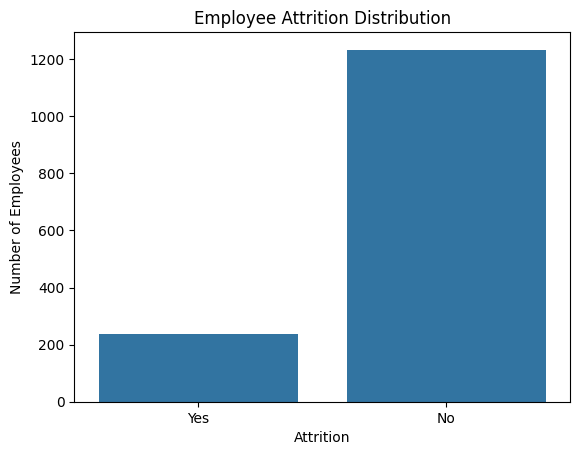

In [35]:
# 1. Check Missing Values
print("Total Missing Values:", df.isnull().sum().sum())

print("\nMissing Values per Column:")
print(df.isnull().sum()[df.isnull().sum() > 0])


# 2. Check Attrition Distribution
print("\nAttrition Distribution:")
print(df["Attrition"].value_counts())


# 3. Check Attrition Percentages
print("\nAttrition Percentages:")
print(df["Attrition"].value_counts(normalize=True) * 100)


# 4. Visualize Attrition Distribution
sns.countplot(data=df, x="Attrition")

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.show()

In [36]:
# Check unique values in potential unnecessary columns

columns_to_check = [
    "EmployeeCount",
    "Over18",
    "StandardHours",
    "EmployeeNumber"
]

for col in columns_to_check:
    print(f"{col}:")
    print("Unique values:", df[col].nunique())
    print(df[col].unique()[:10])
    print("-" * 40)

EmployeeCount:
Unique values: 1
[1]
----------------------------------------
Over18:
Unique values: 1
<StringArray>
['Y']
Length: 1, dtype: str
----------------------------------------
StandardHours:
Unique values: 1
[80]
----------------------------------------
EmployeeNumber:
Unique values: 1470
[ 1  2  4  5  7  8 10 11 12 13]
----------------------------------------


In [37]:
# Summary statistics of numerical columns

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [38]:
# Drop unnecessary columns

columns_to_drop = [
    "EmployeeCount",
    "EmployeeNumber",
    "Over18",
    "StandardHours"
]

df_clean = df.drop(columns=columns_to_drop)

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

df_clean.head()

Original Dataset Shape: (1470, 35)
Cleaned Dataset Shape: (1470, 31)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


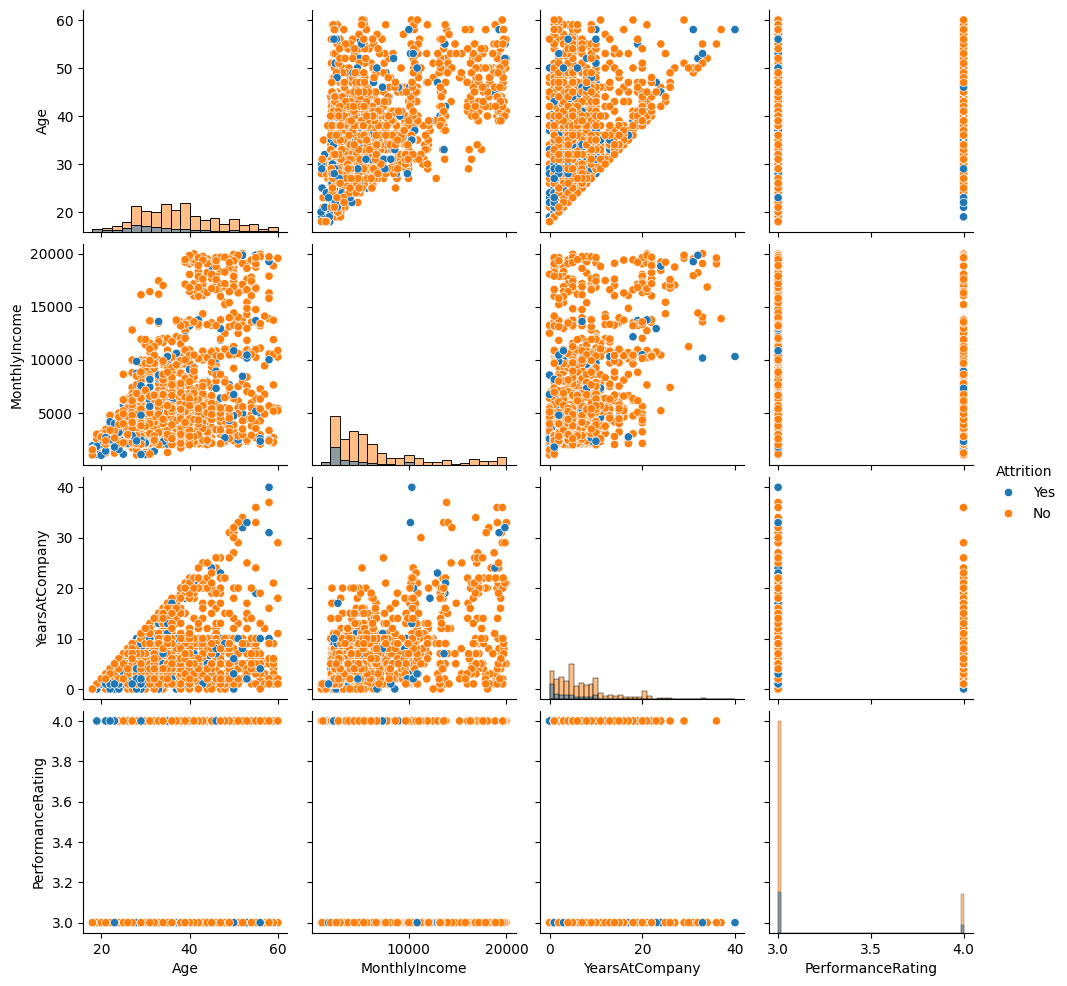

In [39]:
# Pairplot for selected features

pairplot_data = df_clean[
    [
        "Age",
        "MonthlyIncome",
        "YearsAtCompany",
        "PerformanceRating",
        "Attrition"
    ]
]

sns.pairplot(
    pairplot_data,
    hue="Attrition",
    diag_kind="hist"
)

plt.show()

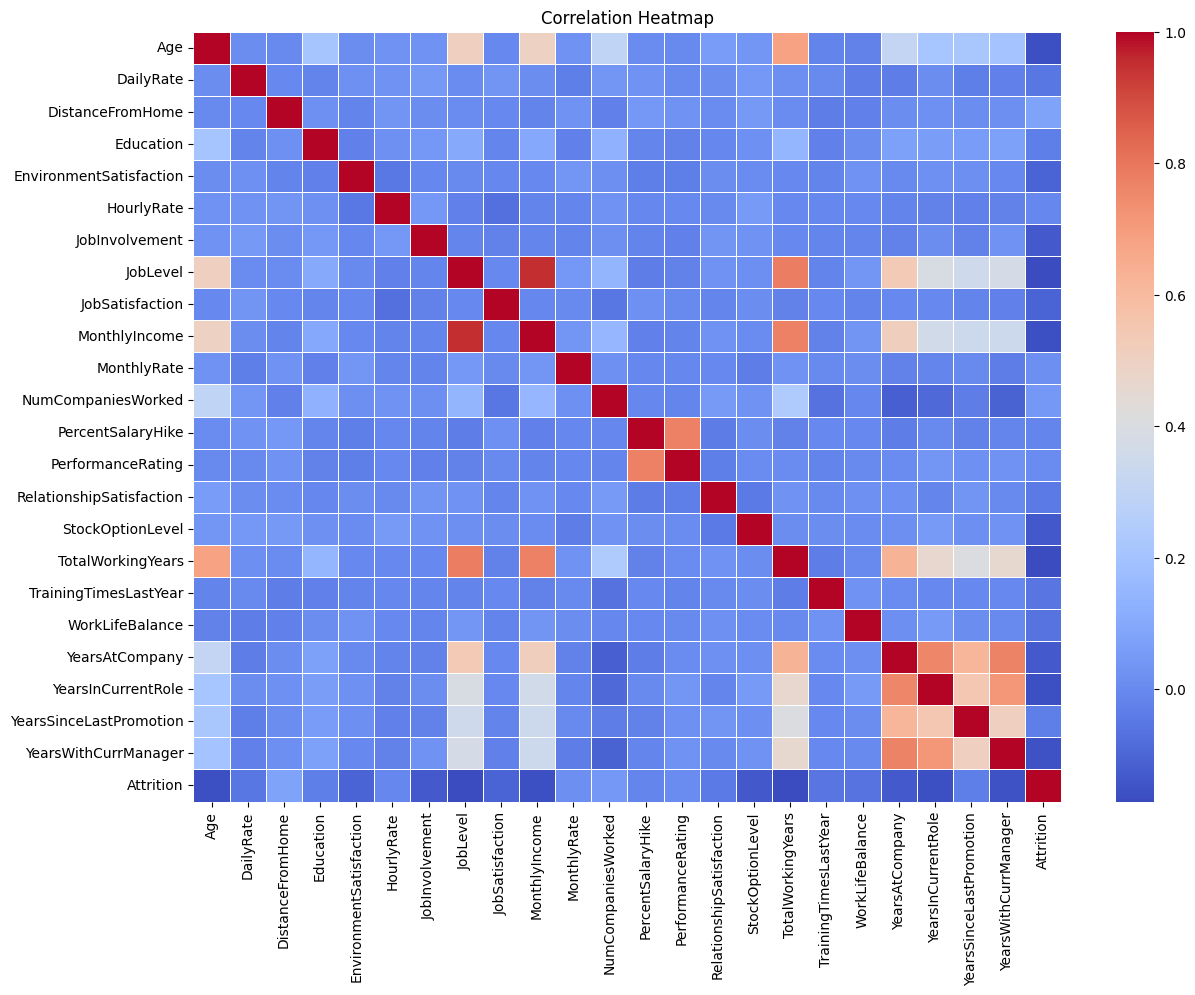

In [40]:
corr_df = df_clean.select_dtypes(include=["number"]).copy()
corr_df["Attrition"] = df_clean["Attrition"].map({"No": 0, "Yes": 1})

plt.figure(figsize=(14, 10))
sns.heatmap(corr_df.corr(), cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

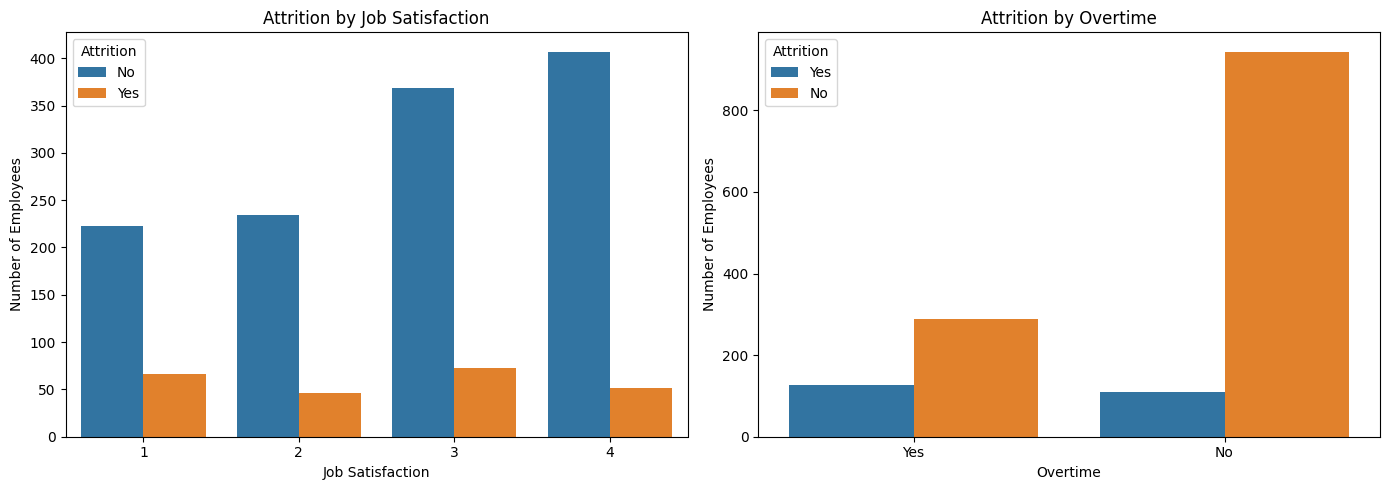

In [41]:
# Attrition Analysis

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=df_clean,
    x="JobSatisfaction",
    hue="Attrition",
    ax=axes[0]
)

axes[0].set_title("Attrition by Job Satisfaction")
axes[0].set_xlabel("Job Satisfaction")
axes[0].set_ylabel("Number of Employees")


sns.countplot(
    data=df_clean,
    x="OverTime",
    hue="Attrition",
    ax=axes[1]
)

axes[1].set_title("Attrition by Overtime")
axes[1].set_xlabel("Overtime")
axes[1].set_ylabel("Number of Employees")

plt.tight_layout()
plt.show()

In [42]:
# Attrition Rate by Job Satisfaction

satisfaction_analysis = pd.crosstab(
    df_clean["JobSatisfaction"],
    df_clean["Attrition"],
    normalize="index"
) * 100

print("Attrition Percentage by Job Satisfaction:")
print(satisfaction_analysis.round(2))


# Attrition Rate by Overtime

overtime_analysis = pd.crosstab(
    df_clean["OverTime"],
    df_clean["Attrition"],
    normalize="index"
) * 100

print("\nAttrition Percentage by Overtime:")
print(overtime_analysis.round(2))

Attrition Percentage by Job Satisfaction:
Attrition           No    Yes
JobSatisfaction              
1                77.16  22.84
2                83.57  16.43
3                83.48  16.52
4                88.67  11.33

Attrition Percentage by Overtime:
Attrition     No    Yes
OverTime               
No         89.56  10.44
Yes        69.47  30.53


In [43]:
df_clean["MonthlyIncome"] = np.log(df_clean["MonthlyIncome"])

print("MonthlyIncome skewness after log:", df_clean["MonthlyIncome"].skew())

MonthlyIncome skewness after log: 0.2861922926389174


In [44]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics import classification_report, confusion_matrix

In [45]:
# Separate Features and Target

X = df_clean.drop(columns=["Attrition"])
y = df_clean["Attrition"].map({"No": 0, "Yes": 1})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (1470, 30)
Target Shape: (1470,)

Target Distribution:
Attrition
0    1233
1     237
Name: count, dtype: int64


In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features: (1176, 30)
Testing Features: (294, 30)

Training Target Distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Testing Target Distribution:
Attrition
0    247
1     47
Name: count, dtype: int64


In [47]:
# Identify Numerical and Categorical Columns

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Number of Numerical Features:", len(numeric_features))
print("Number of Categorical Features:", len(categorical_features))

print("\nCategorical Features:")
print(categorical_features)

Number of Numerical Features: 23
Number of Categorical Features: 7

Categorical Features:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [48]:
# Preprocessing Pipelines

numeric_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


In [49]:
# Logistic Regression Model

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [50]:
# Logistic Regression Evaluation

y_pred_lr = logistic_model.predict(X_test)

print("Logistic Regression Classification Report:\n")
print(classification_report(
    y_test,
    y_pred_lr,
    labels=[0, 1],
    target_names=["No Attrition", "Attrition"],
    zero_division=0
))

print("Confusion Matrix:\n")
print(confusion_matrix(y_test, y_pred_lr, labels=[0, 1]))

Logistic Regression Classification Report:

              precision    recall  f1-score   support

No Attrition       0.89      0.96      0.93       247
   Attrition       0.67      0.38      0.49        47

    accuracy                           0.87       294
   macro avg       0.78      0.67      0.71       294
weighted avg       0.86      0.87      0.86       294

Confusion Matrix:

[[238   9]
 [ 29  18]]


In [51]:
# Support Vector Classifier Model

svc_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC())
])

svc_model.fit(X_train, y_train)

print("SVC Model Trained Successfully!")

SVC Model Trained Successfully!


In [52]:
# SVC Evaluation

y_pred_svc = svc_model.predict(X_test)

print("SVC Classification Report:\n")
print(classification_report(
    y_test,
    y_pred_svc,
    labels=[0, 1],
    target_names=["No Attrition", "Attrition"],
    zero_division=0
))

print("Confusion Matrix:\n")
print(confusion_matrix(y_test, y_pred_svc, labels=[0, 1]))

SVC Classification Report:

              precision    recall  f1-score   support

No Attrition       0.87      0.99      0.92       247
   Attrition       0.82      0.19      0.31        47

    accuracy                           0.86       294
   macro avg       0.84      0.59      0.62       294
weighted avg       0.86      0.86      0.83       294

Confusion Matrix:

[[245   2]
 [ 38   9]]


In [53]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": y_pred_lr,
    "SVC": y_pred_svc
}

results = []

for model_name, y_pred in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="F1-Score",
    ascending=False
)

comparison_df.round(3)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.871,0.667,0.383,0.486
1,SVC,0.864,0.818,0.191,0.310
